<a href="https://colab.research.google.com/github/SeoulTechPSE/tong_lectures/blob/main/2_quantum/topics_in_qm/aqm_ch04_figures.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

*Topics in Quantum Mechanics* — `aqm_ch04_figures.ipynb` · after D. Tong's Cambridge lecture notes · Kee-Youn Yoo, Process Systems Laboratory, SeoulTech

# AQM Chapter 4 — Phonons: Figures
Run in Colab. Last cell auto-downloads `ch04_figures.zip`.

| Fig | Content |
|-----|--------|
| 01 | Monatomic chain: dispersion, group velocity, DOS |
| 02 | Normal modes: atomic displacements at various $k$ |
| 03 | Diatomic chain: acoustic + optical branches, phonon gap |
| 04 | Acoustic vs optical mode: atomic motion patterns |
| 05 | Peierls instability: half-filled band dimerisation |
| 06 | Phonon quantisation: energy levels, Bose-Einstein occupation |
| 07 | Debye vs Einstein specific heat, $T^3$ law |
| 08 | 3D phonon dispersion: LA, TA, LO, TO branches |
| 09 | Phonon DOS, Van Hove singularities, mean square displacement |
| 10 | Bloch-Gruneisen resistivity, Matthiessen's rule |


In [1]:

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.patches import FancyArrowPatch, Circle, FancyArrow
from matplotlib.collections import LineCollection
import os

plt.rcParams.update({
    'figure.facecolor': '#1e1e2e', 'axes.facecolor': '#1e1e2e',
    'text.color': '#cdd6f4', 'axes.labelcolor': '#cdd6f4',
    'xtick.color': '#cdd6f4', 'ytick.color': '#cdd6f4',
    'axes.edgecolor': '#45475a', 'grid.color': '#313244',
    'font.family': 'DejaVu Sans', 'font.size': 12,
    'axes.titlesize': 13, 'axes.titleweight': 'bold',
    'mathtext.fontset': 'cm',
})
BLUE='#7ec8e3'; YELLOW='#f9c74f'; GREEN='#90ee90'
RED='#e07070'; PURPLE='#c792ea'; ORANGE='#ffb347'; BG='#1e1e2e'
os.makedirs('figures/ch04', exist_ok=True)
SAVE = lambda n: plt.savefig(f'figures/ch04/{n}', dpi=150,
                              bbox_inches='tight', facecolor=BG)
print('Setup complete.')


Setup complete.


## Fig 01 — Monatomic Chain

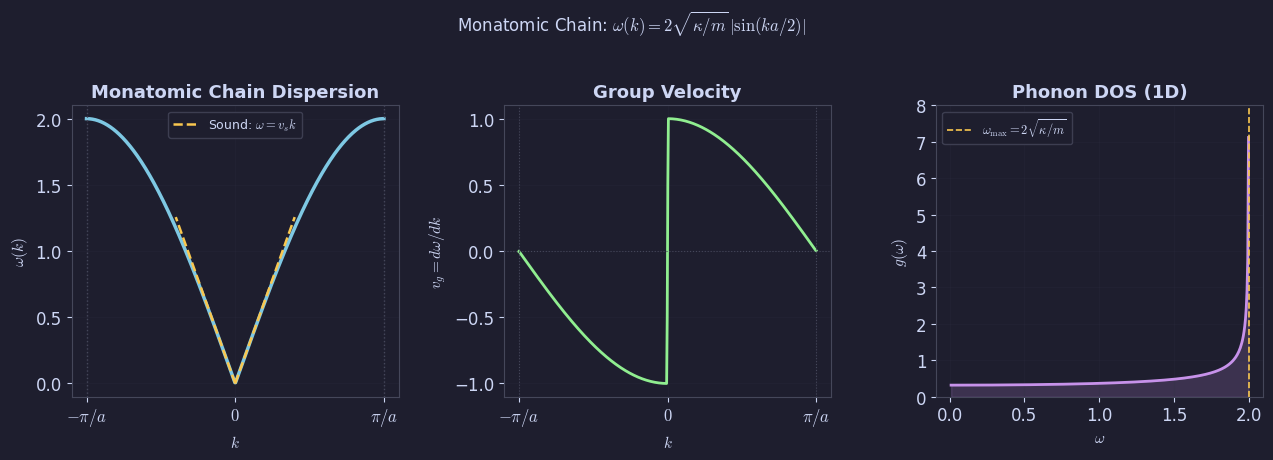

Fig 01 saved.


In [2]:

# Fig 01: Monatomic chain — dispersion relation and atomic motion
# omega(k) = 2*sqrt(kappa/m) * |sin(ka/2)|
# Group velocity, phase velocity

a = 1.0
kappa_over_m = 1.0   # kappa/m = 1
omega_max = 2.0 * np.sqrt(kappa_over_m)

k_bz = np.linspace(-np.pi/a, np.pi/a, 500)
omega = 2.0 * np.sqrt(kappa_over_m) * np.abs(np.sin(k_bz * a / 2))

# Group and phase velocities
v_group = np.gradient(omega, k_bz)
# Avoid division by zero at k=0
with np.errstate(invalid='ignore', divide='ignore'):
    v_phase = np.where(np.abs(k_bz) > 1e-6, omega / k_bz, omega_max * a / 2)

fig, axes = plt.subplots(1, 3, figsize=(13, 4.5))

# Dispersion
ax = axes[0]
ax.plot(k_bz, omega, color=BLUE, lw=2.5)
# Sound velocity line at small k
k_small = np.linspace(0, 0.4*np.pi/a, 100)
v_sound = np.sqrt(kappa_over_m) * a
ax.plot(k_small, v_sound * k_small, color=YELLOW, lw=1.8, ls='--',
        label=r'Sound: $\omega = v_s k$')
ax.plot(-k_small, v_sound * k_small, color=YELLOW, lw=1.8, ls='--')
for xb in [-np.pi/a, np.pi/a]:
    ax.axvline(xb, color='#45475a', lw=1., ls=':')
ax.set_xlabel(r'$k$', fontsize=11)
ax.set_ylabel(r'$\omega(k)$', fontsize=11)
ax.set_title('Monatomic Chain Dispersion', color='#cdd6f4')
ax.set_xticks([-np.pi/a, 0, np.pi/a])
ax.set_xticklabels([r'$-\pi/a$', '$0$', r'$\pi/a$'])
ax.legend(fontsize=9, facecolor=BG, edgecolor='#45475a', labelcolor='#cdd6f4')
ax.grid(True, alpha=0.2)

# Group velocity
axes[1].plot(k_bz, v_group, color=GREEN, lw=2.)
axes[1].axhline(0, color='#45475a', lw=0.8, ls=':')
for xb in [-np.pi/a, np.pi/a]:
    axes[1].axvline(xb, color='#45475a', lw=0.8, ls=':')
axes[1].set_xlabel(r'$k$', fontsize=11)
axes[1].set_ylabel(r'$v_g = d\omega/dk$', fontsize=11)
axes[1].set_title('Group Velocity', color='#cdd6f4')
axes[1].set_xticks([-np.pi/a, 0, np.pi/a])
axes[1].set_xticklabels([r'$-\pi/a$', '$0$', r'$\pi/a$'])
axes[1].grid(True, alpha=0.2)

# Phonon density of states (1D: Van Hove singularity at BZ boundary)
omega_vals = np.linspace(0.01, omega_max*0.999, 400)
# g(omega) = (2/pi) * 1/sqrt(omega_max^2 - omega^2)
g_omega = (2.0/np.pi) / np.sqrt(omega_max**2 - omega_vals**2)
g_omega = np.clip(g_omega, 0, 8)
axes[2].plot(omega_vals, g_omega, color=PURPLE, lw=2.)
axes[2].fill_between(omega_vals, 0, g_omega, color=PURPLE, alpha=0.18)
axes[2].axvline(omega_max, color=YELLOW, lw=1.2, ls='--',
                label=r'$\omega_{\rm max} = 2\sqrt{\kappa/m}$')
axes[2].set_xlabel(r'$\omega$', fontsize=11)
axes[2].set_ylabel(r'$g(\omega)$', fontsize=11)
axes[2].set_title('Phonon DOS (1D)', color='#cdd6f4')
axes[2].set_ylim(0, 8)
axes[2].legend(fontsize=9, facecolor=BG, edgecolor='#45475a', labelcolor='#cdd6f4')
axes[2].grid(True, alpha=0.2)

plt.suptitle(r'Monatomic Chain: $\omega(k)=2\sqrt{\kappa/m}\,|\sin(ka/2)|$',
             color='#cdd6f4', fontsize=12, y=1.02)
plt.tight_layout()
SAVE('fig01_monatomic_chain.png'); plt.show(); print('Fig 01 saved.')


## Fig 02 — Normal Modes

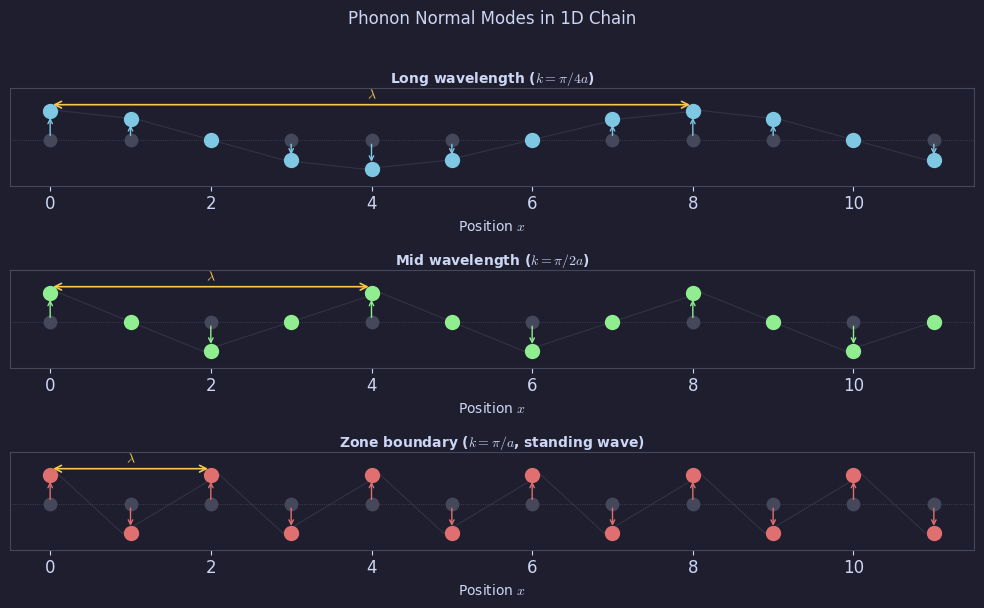

Fig 02 saved.


In [3]:

# Fig 02: Snapshots of phonon normal modes at different k
# Shows long-wavelength (acoustic) and short-wavelength modes

a  = 1.0
N  = 12   # atoms in the chain
x0 = np.arange(N) * a

fig, axes = plt.subplots(3, 1, figsize=(10, 6))

k_vals  = [0.25*np.pi/a, np.pi/(2*a), np.pi/a]
labels  = [r'Long wavelength ($k=\pi/4a$)',
           r'Mid wavelength ($k=\pi/2a$)',
           r'Zone boundary ($k=\pi/a$, standing wave)']
cols    = [BLUE, GREEN, RED]

for ax, k, lbl, col in zip(axes, k_vals, labels, cols):
    # Equilibrium positions (grey dots)
    ax.scatter(x0, np.zeros(N), color='#45475a', s=80, zorder=3,
               label='Equilibrium')
    # Displaced positions
    u = 0.35 * np.cos(k * x0)
    ax.scatter(x0, u, color=col, s=100, zorder=4)
    # Springs (lines between atoms)
    for i in range(N-1):
        ax.plot([x0[i]+u[i]*0.3, x0[i+1]+u[i+1]*0.3],
                [u[i], u[i+1]], color='#45475a', lw=0.8, alpha=0.5)
    # Displacement arrows
    for i in range(N):
        if abs(u[i]) > 0.02:
            ax.annotate('', xy=(x0[i], u[i]*0.85),
                        xytext=(x0[i], 0.02*np.sign(u[i])),
                        arrowprops=dict(arrowstyle='->', color=col,
                                        lw=1.0, mutation_scale=8))
    # Wavelength indicator
    lambda_k = 2*np.pi/k if k > 0 else 999
    if lambda_k < (N-1)*a:
        ax.annotate('', xy=(x0[0]+lambda_k, 0.42),
                    xytext=(x0[0], 0.42),
                    arrowprops=dict(arrowstyle='<->', color=YELLOW, lw=1.2))
        ax.text(x0[0]+lambda_k/2, 0.48, r'$\lambda$',
                color=YELLOW, ha='center', fontsize=10)
    ax.set_xlim(-0.5, (N-0.5)*a)
    ax.set_ylim(-0.55, 0.62)
    ax.set_title(lbl, color='#cdd6f4', fontsize=10, pad=3)
    ax.set_yticks([]); ax.set_xlabel(r'Position $x$', fontsize=10)
    ax.grid(False)
    ax.axhline(0, color='#45475a', lw=0.6, ls=':')

plt.suptitle('Phonon Normal Modes in 1D Chain', color='#cdd6f4',
             fontsize=12, y=1.01)
plt.tight_layout()
SAVE('fig02_normal_modes.png'); plt.show(); print('Fig 02 saved.')


## Fig 03 — Diatomic Chain

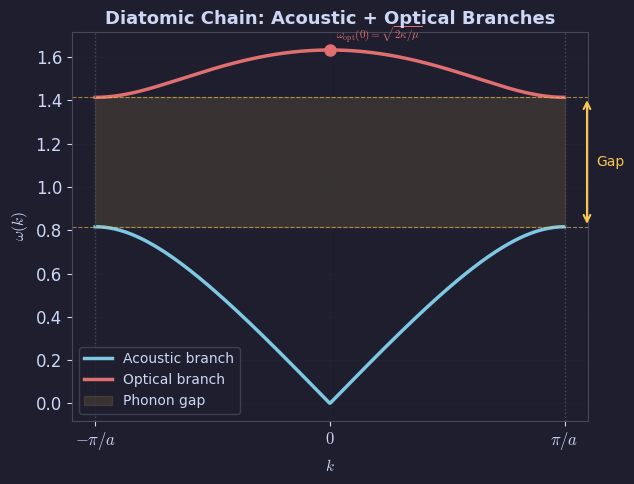

Fig 03 saved.


In [4]:

# Fig 03: Diatomic chain dispersion — acoustic + optical branches
# Two masses M, m per unit cell (M > m), alternating springs kappa
# omega^2 = kappa/mu * [1 +/- sqrt(1 - 4*mu^2/(Mm) * sin^2(ka/2))]
# where mu = Mm/(M+m) is reduced mass

a = 1.0   # unit cell length
M = 3.0   # heavy mass
m = 1.0   # light mass
kappa = 1.0
mu = M*m/(M+m)

k = np.linspace(-np.pi/a, np.pi/a, 600)
discriminant = 1 - 4*(mu**2)/(M*m) * np.sin(k*a/2)**2
discriminant = np.clip(discriminant, 0, None)

omega_sq_plus  = kappa/mu * (1 + np.sqrt(discriminant))
omega_sq_minus = kappa/mu * (1 - np.sqrt(discriminant))
omega_opt  = np.sqrt(np.abs(omega_sq_plus))
omega_ac   = np.sqrt(np.abs(omega_sq_minus))

# Key values
omega_opt_k0  = np.sqrt(2*kappa/mu)        # optical at k=0
omega_ac_kmax = np.sqrt(2*kappa/M)         # acoustic at BZ boundary
omega_opt_kmax = np.sqrt(2*kappa/m)        # optical at BZ boundary
gap_bottom = omega_ac_kmax
gap_top    = omega_opt_kmax

fig, ax = plt.subplots(figsize=(6.5, 5))
ax.plot(k, omega_ac,  color=BLUE,   lw=2.5, label='Acoustic branch')
ax.plot(k, omega_opt, color=RED,    lw=2.5, label='Optical branch')

# BZ boundaries
for xb in [-np.pi/a, np.pi/a]:
    ax.axvline(xb, color='#45475a', lw=1., ls=':')

# Gap shading
ax.fill_between([-np.pi/a, np.pi/a], gap_bottom, gap_top,
                color=YELLOW, alpha=0.12, label='Phonon gap')
ax.axhline(gap_bottom, color=YELLOW, lw=0.8, ls='--', alpha=0.6)
ax.axhline(gap_top,    color=YELLOW, lw=0.8, ls='--', alpha=0.6)

# Gap annotation
ax.annotate('', xy=(np.pi/a+0.3, gap_top),
            xytext=(np.pi/a+0.3, gap_bottom),
            arrowprops=dict(arrowstyle='<->', color=YELLOW, lw=1.5))
ax.text(np.pi/a+0.42, (gap_top+gap_bottom)/2, 'Gap',
        color=YELLOW, fontsize=10, va='center')

# k=0 labels
ax.plot(0, omega_opt_k0, 'o', color=RED, ms=8, zorder=5)
ax.text(0.08, omega_opt_k0+0.05,
        r'$\omega_{\rm opt}(0)=\sqrt{2\kappa/\mu}$',
        color=RED, fontsize=8)

ax.set_xlabel(r'$k$', fontsize=11)
ax.set_ylabel(r'$\omega(k)$', fontsize=11)
ax.set_title('Diatomic Chain: Acoustic + Optical Branches', color='#cdd6f4')
ax.set_xticks([-np.pi/a, 0, np.pi/a])
ax.set_xticklabels([r'$-\pi/a$', '$0$', r'$\pi/a$'])
ax.legend(fontsize=10, facecolor=BG, edgecolor='#45475a', labelcolor='#cdd6f4')
ax.grid(True, alpha=0.2)

plt.tight_layout()
SAVE('fig03_diatomic_chain.png'); plt.show(); print('Fig 03 saved.')


## Fig 04 — Acoustic vs Optical Mode Motion

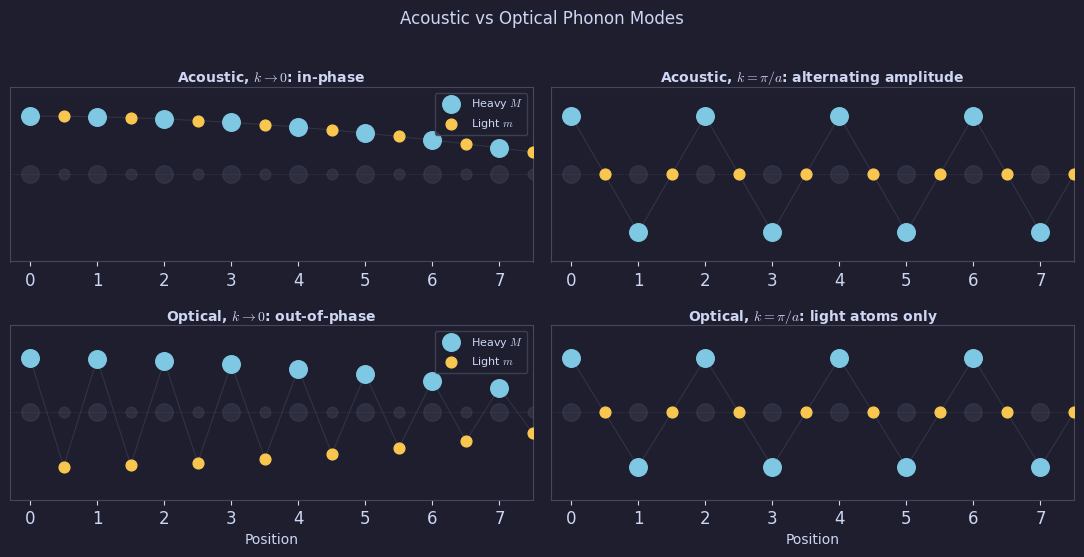

Fig 04 saved.


In [5]:

# Fig 04: Atomic motion in acoustic vs optical mode at k=0 and k=pi/a
# Acoustic k~0: both atoms move together (long-wavelength sound)
# Optical k~0: atoms move in opposition (dipole-active)
# BZ boundary: one species stationary, other oscillates

N_cell = 8
fig, axes = plt.subplots(2, 2, figsize=(11, 5.5))

configs = [
    (0, 'acoustic', r'Acoustic, $k\to 0$: in-phase'),
    (1, 'acoustic', r'Acoustic, $k=\pi/a$: alternating amplitude'),
    (0, 'optical',  r'Optical, $k\to 0$: out-of-phase'),
    (1, 'optical',  r'Optical, $k=\pi/a$: light atoms only'),
]

k_vals_plot = [0.05*np.pi, np.pi]   # small k, BZ boundary

for ax, (ki, mode, title) in zip(axes.flat, configs):
    k_plot = k_vals_plot[ki]
    a_cell = 1.0

    # Heavy (M) at 0, light (m) at a/2 in each cell
    x_heavy = np.arange(N_cell) * a_cell
    x_light = x_heavy + 0.5*a_cell

    # Amplitudes at given k
    if mode == 'acoustic':
        # Both move with similar amplitude; relative phase depends on k
        A_heavy = 0.30 * np.cos(k_plot * x_heavy)
        A_light = 0.30 * np.cos(k_plot * x_light)
    else:
        # Optical: heavy moves one way, light the other, amplitude ratio ~ m/M at k=0
        ratio = 1.0 / 3.0   # m/M
        A_heavy = 0.28 * np.cos(k_plot * x_heavy)
        A_light = -ratio * 0.28/ratio * np.cos(k_plot * x_light)

    # Draw equilibrium (grey) and displaced (coloured)
    ax.scatter(x_heavy, np.zeros(N_cell), color='#45475a', s=160,
               zorder=2, alpha=0.4)
    ax.scatter(x_light, np.zeros(N_cell), color='#45475a', s=60,
               zorder=2, alpha=0.4)
    ax.scatter(x_heavy, A_heavy, color=BLUE,   s=160, zorder=4,
               label='Heavy $M$')
    ax.scatter(x_light, A_light, color=YELLOW, s=60,  zorder=4,
               label='Light $m$')

    # Springs
    all_x_eq = np.sort(np.concatenate([x_heavy, x_light]))
    all_disp  = np.concatenate([A_heavy, A_light])
    sort_idx  = np.argsort(np.concatenate([x_heavy, x_light]))
    all_x_eq2 = np.concatenate([x_heavy, x_light])[sort_idx]
    all_disp2 = all_disp[sort_idx]
    for i in range(len(all_x_eq2)-1):
        ax.plot([all_x_eq2[i], all_x_eq2[i+1]],
                [all_disp2[i], all_disp2[i+1]],
                color='#45475a', lw=0.8, alpha=0.5)

    ax.axhline(0, color='#45475a', lw=0.5, ls=':')
    ax.set_xlim(-0.3, (N_cell-0.5)*a_cell)
    ax.set_ylim(-0.45, 0.45)
    ax.set_title(title, color='#cdd6f4', fontsize=10, pad=3)
    ax.set_yticks([])
    if ax in axes[1]:
        ax.set_xlabel('Position', fontsize=10)
    if ki == 0:
        ax.legend(fontsize=8, facecolor=BG, edgecolor='#45475a',
                  labelcolor='#cdd6f4', loc='upper right')

plt.suptitle('Acoustic vs Optical Phonon Modes', color='#cdd6f4',
             fontsize=12, y=1.01)
plt.tight_layout()
SAVE('fig04_acoustic_optical_modes.png'); plt.show(); print('Fig 04 saved.')


## Fig 05 — Peierls Instability

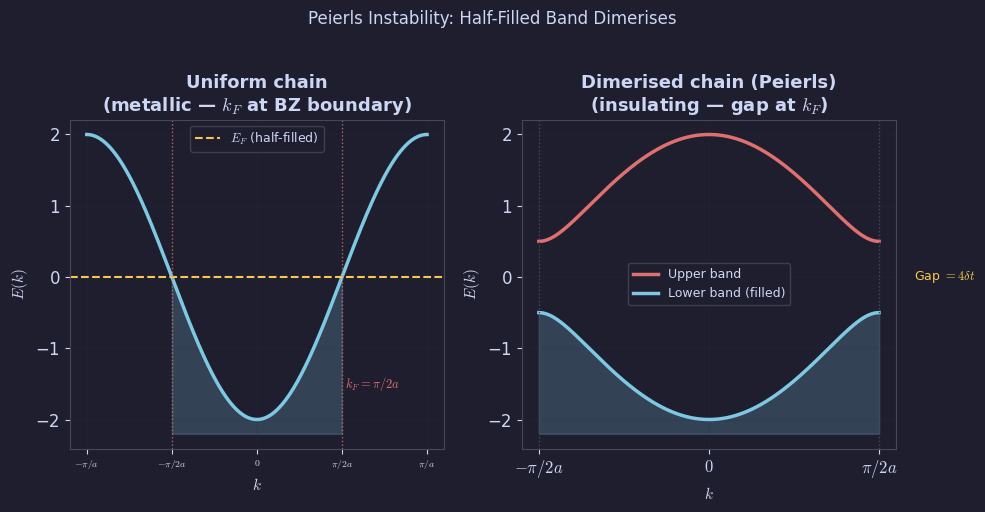

Fig 05 saved.


In [6]:

# Fig 05: Peierls instability — half-filled band
# Uniform chain: metallic with Fermi surface at k=+/-pi/2a
# Dimerised chain: unit cell doubles, BZ halves -> gap opens at k=+/-pi/2a

a  = 1.0
t0 = 1.0   # hopping in uniform chain
delta = 0.25   # dimerisation: t1 = t0+delta, t2 = t0-delta

k_uniform   = np.linspace(-np.pi/a, np.pi/a, 600)
E_uniform   = -2*t0*np.cos(k_uniform*a)

# Dimerised: new unit cell = 2a, BZ = [-pi/2a, pi/2a]
# H(k) = [[0, t1+t2*e^{ika}], [conj, 0]] -> E = +/- sqrt(t1^2+t2^2+2*t1*t2*cos(2ka))
k_dim = np.linspace(-np.pi/(2*a), np.pi/(2*a), 600)
t1 = t0 + delta; t2 = t0 - delta
E_dim_sq = t1**2 + t2**2 + 2*t1*t2*np.cos(2*k_dim*a)
E_dim_pos =  np.sqrt(np.abs(E_dim_sq))
E_dim_neg = -np.sqrt(np.abs(E_dim_sq))

kF = np.pi / (2*a)   # half-filling Fermi momentum

fig, axes = plt.subplots(1, 2, figsize=(10, 5))

# Uniform chain
ax = axes[0]
ax.plot(k_uniform, E_uniform, color=BLUE, lw=2.5)
ax.fill_between(k_uniform, E_uniform.min()-0.2, E_uniform,
                where=(E_uniform <= 0), color=BLUE, alpha=0.22)
ax.axhline(0, color=YELLOW, lw=1.5, ls='--', label='$E_F$ (half-filled)')
for xb in [-kF, kF]:
    ax.axvline(xb, color=RED, lw=1., ls=':', alpha=0.8)
ax.text(kF+0.05, -1.5, r'$k_F=\pi/2a$', color=RED, fontsize=9, va='center')
ax.set_title('Uniform chain\n(metallic — $k_F$ at BZ boundary)', color='#cdd6f4')
ax.set_xlabel(r'$k$', fontsize=11); ax.set_ylabel(r'$E(k)$', fontsize=11)
ax.set_xticks([-np.pi/a, -kF, 0, kF, np.pi/a])
ax.set_xticklabels([r'$-\pi/a$', r'$-\pi/2a$', '$0$', r'$\pi/2a$', r'$\pi/a$'],
                    fontsize=7)
ax.legend(fontsize=9, facecolor=BG, edgecolor='#45475a', labelcolor='#cdd6f4')
ax.grid(True, alpha=0.2)

# Dimerised chain
ax2 = axes[1]
ax2.plot(k_dim, E_dim_pos, color=RED,  lw=2.5, label='Upper band')
ax2.plot(k_dim, E_dim_neg, color=BLUE, lw=2.5, label='Lower band (filled)')
ax2.fill_between(k_dim, E_dim_neg.min()-0.2, E_dim_neg,
                 color=BLUE, alpha=0.22)
# Gap annotation
gap_size = 2*(t1 - t2)
ax2.annotate('', xy=(np.pi/(2*a)+0.2, t1-t2),
             xytext=(np.pi/(2*a)+0.2, -(t1-t2)),
             arrowprops=dict(arrowstyle='<->', color=YELLOW, lw=1.5))
ax2.text(np.pi/(2*a)+0.32, 0,
         f'Gap $= 4\\delta t$', color=YELLOW, fontsize=9, va='center')
# New BZ boundary
for xb in [-np.pi/(2*a), np.pi/(2*a)]:
    ax2.axvline(xb, color='#45475a', lw=1., ls=':')
ax2.set_title('Dimerised chain (Peierls)\n(insulating — gap at $k_F$)',
              color='#cdd6f4')
ax2.set_xlabel(r'$k$', fontsize=11); ax2.set_ylabel(r'$E(k)$', fontsize=11)
ax2.set_xticks([-np.pi/(2*a), 0, np.pi/(2*a)])
ax2.set_xticklabels([r'$-\pi/2a$', '$0$', r'$\pi/2a$'])
ax2.legend(fontsize=9, facecolor=BG, edgecolor='#45475a', labelcolor='#cdd6f4')
ax2.grid(True, alpha=0.2)

plt.suptitle('Peierls Instability: Half-Filled Band Dimerises',
             color='#cdd6f4', fontsize=12, y=1.02)
plt.tight_layout()
SAVE('fig05_peierls.png'); plt.show(); print('Fig 05 saved.')


## Fig 06 — Phonon Quantisation

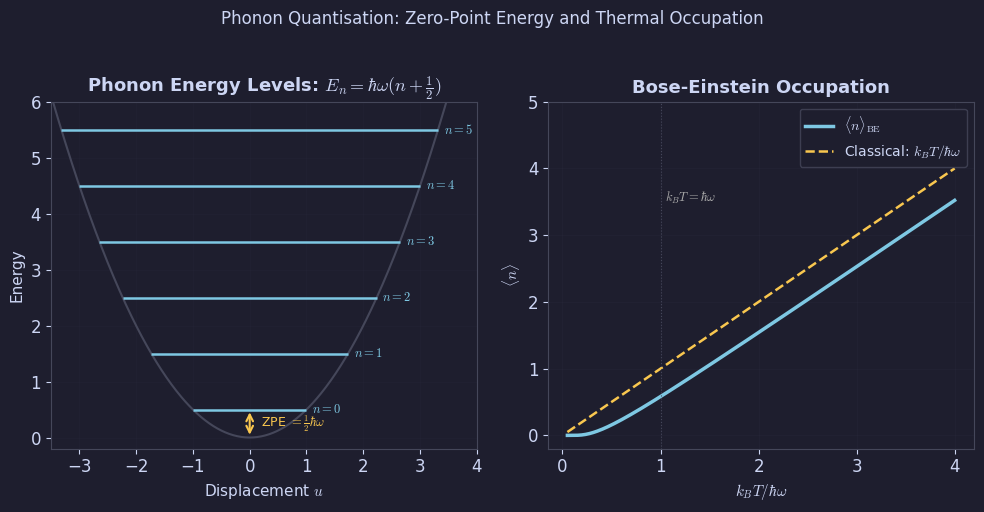

Fig 06 saved.


In [7]:

# Fig 06: Quantum harmonic oscillator (phonon) energy levels
# E_n = hbar*omega*(n + 1/2), n = 0,1,2,...
# Illustrates zero-point energy, thermal occupation (Bose-Einstein)

hbar = 1.; omega = 1.
n_levels = 6
E_n = np.array([hbar*omega*(n + 0.5) for n in range(n_levels)])

# Parabolic potential
x = np.linspace(-3.5, 3.5, 400)
V = 0.5 * omega**2 * x**2

# Bose-Einstein occupation at several temperatures
k_B = 1.
T_vals  = [0.5, 1.0, 2.0]
T_cols  = [BLUE, GREEN, RED]
T_lbls  = ['$k_BT = 0.5\\hbar\\omega$',
           '$k_BT = \\hbar\\omega$',
           '$k_BT = 2\\hbar\\omega$']

fig, axes = plt.subplots(1, 2, figsize=(10, 5))

# Left: energy levels in potential
ax = axes[0]
ax.plot(x, V, color='#45475a', lw=1.5)
for n, En in enumerate(E_n):
    # Classical turning points
    x_turn = np.sqrt(2*En) / omega
    x_lev  = np.linspace(-x_turn, x_turn, 100)
    ax.hlines(En, -x_turn, x_turn, colors=BLUE, lw=1.8)
    ax.text(x_turn+0.1, En, f'$n={n}$', color=BLUE, va='center', fontsize=9)

# Zero-point energy arrow
ax.annotate('', xy=(0, E_n[0]), xytext=(0, 0),
            arrowprops=dict(arrowstyle='<->', color=YELLOW, lw=1.5))
ax.text(0.2, E_n[0]/2,
        r'ZPE $= \frac{1}{2}\hbar\omega$',
        color=YELLOW, fontsize=9, va='center')
ax.set_xlim(-3.5, 4.0); ax.set_ylim(-0.2, E_n[-1]+0.5)
ax.set_xlabel(r'Displacement $u$', fontsize=11)
ax.set_ylabel(r'Energy', fontsize=11)
ax.set_title(r'Phonon Energy Levels: $E_n = \hbar\omega(n+\frac{1}{2})$',
             color='#cdd6f4')
ax.grid(True, alpha=0.15)

# Right: Bose-Einstein occupation <n> vs temperature
k_BT = np.linspace(0.05, 4.0, 300)
for T_c, col, lbl in zip([0.5, 1.0, 2.0], T_cols, T_lbls):
    n_BE_all = 1.0 / (np.exp(1.0/k_BT) - 1.0 + 1e-12)

ax2 = axes[1]
n_BE = 1.0 / (np.exp(hbar*omega / (k_B*k_BT)) - 1 + 1e-12)
ax2.plot(k_BT, n_BE, color=BLUE, lw=2.5, label=r'$\langle n\rangle_{\rm BE}$')

# Classical limit
ax2.plot(k_BT, k_BT/( hbar*omega), color=YELLOW, lw=1.8, ls='--',
         label=r'Classical: $k_BT/\hbar\omega$')

ax2.axvline(1.0, color='#45475a', lw=0.8, ls=':')
ax2.text(1.05, 3.5, r'$k_BT=\hbar\omega$', color='#aaa', fontsize=9)
ax2.set_xlabel(r'$k_BT/\hbar\omega$', fontsize=11)
ax2.set_ylabel(r'$\langle n\rangle$', fontsize=11)
ax2.set_title('Bose-Einstein Occupation', color='#cdd6f4')
ax2.set_ylim(-0.2, 5)
ax2.legend(fontsize=10, facecolor=BG, edgecolor='#45475a', labelcolor='#cdd6f4')
ax2.grid(True, alpha=0.2)

plt.suptitle('Phonon Quantisation: Zero-Point Energy and Thermal Occupation',
             color='#cdd6f4', fontsize=12, y=1.02)
plt.tight_layout()
SAVE('fig06_phonon_quantisation.png'); plt.show(); print('Fig 06 saved.')


## Fig 07 — Specific Heat

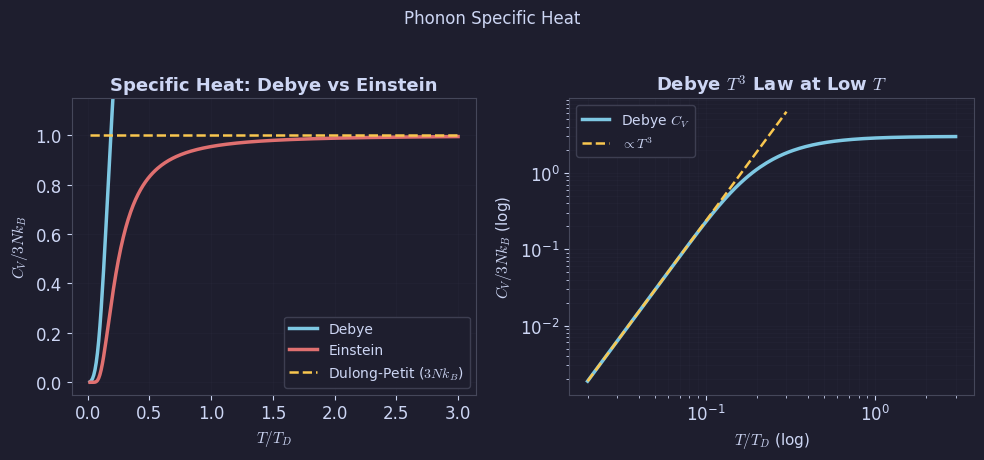

Fig 07 saved.


In [8]:

# Fig 07: Debye and Einstein models of phonon specific heat
# Debye: g(omega) ~ omega^2 up to omega_D; C_V ~ T^3 at low T
# Einstein: single frequency omega_E; C_V ~ (hbar*omega_E/kT)^2 * exp(-hbar*omega_E/kT)

from scipy.integrate import quad

k_B = 1.; hbar = 1.
T_arr = np.linspace(0.02, 3.0, 300)

# Debye model: C_V / 3Nk_B
def debye_cv(T, T_D=1.0):
    x_D = T_D / T
    def integrand(x):
        return x**4 * np.exp(x) / (np.exp(x) - 1 + 1e-30)**2
    integral, _ = quad(integrand, 1e-6, x_D)
    return 3 * (T/T_D)**3 * integral   # C_V/(3Nk_B)

# Einstein model: C_V / 3Nk_B
def einstein_cv(T, T_E=0.75):
    x = T_E / T
    return x**2 * np.exp(x) / (np.exp(x) - 1 + 1e-30)**2

C_debye   = np.array([debye_cv(T)   for T in T_arr])
C_einstein= np.array([einstein_cv(T) for T in T_arr])
C_dulong  = np.ones_like(T_arr)   # Dulong-Petit: C = 3Nk_B

fig, axes = plt.subplots(1, 2, figsize=(10, 4.5))

# Linear scale
ax = axes[0]
ax.plot(T_arr, C_debye,    color=BLUE,   lw=2.5, label='Debye')
ax.plot(T_arr, C_einstein, color=RED,    lw=2.5, label='Einstein')
ax.plot(T_arr, C_dulong,   color=YELLOW, lw=1.8, ls='--',
        label='Dulong-Petit ($3Nk_B$)')
ax.set_xlabel(r'$T/T_D$', fontsize=11)
ax.set_ylabel(r'$C_V / 3Nk_B$', fontsize=11)
ax.set_title('Specific Heat: Debye vs Einstein', color='#cdd6f4')
ax.legend(fontsize=10, facecolor=BG, edgecolor='#45475a', labelcolor='#cdd6f4')
ax.set_ylim(-0.05, 1.15)
ax.grid(True, alpha=0.2)

# Log-log to show T^3 law
T_log = np.linspace(0.02, 3.0, 300)
C_log = np.array([debye_cv(T) for T in T_log])
ax2 = axes[1]
ax2.loglog(T_log, C_log, color=BLUE, lw=2.5, label='Debye $C_V$')
# T^3 reference line
T_ref = np.array([0.02, 0.3])
ax2.loglog(T_ref, 4*np.pi**4/5*(T_ref)**3, color=YELLOW, lw=1.8, ls='--',
           label=r'$\propto T^3$')
ax2.set_xlabel(r'$T/T_D$ (log)', fontsize=11)
ax2.set_ylabel(r'$C_V/3Nk_B$ (log)', fontsize=11)
ax2.set_title(r'Debye $T^3$ Law at Low $T$', color='#cdd6f4')
ax2.legend(fontsize=10, facecolor=BG, edgecolor='#45475a', labelcolor='#cdd6f4')
ax2.grid(True, alpha=0.2, which='both')

plt.suptitle('Phonon Specific Heat', color='#cdd6f4', fontsize=12, y=1.02)
plt.tight_layout()
SAVE('fig07_specific_heat.png'); plt.show(); print('Fig 07 saved.')


## Fig 08 — 3D Phonon Dispersion

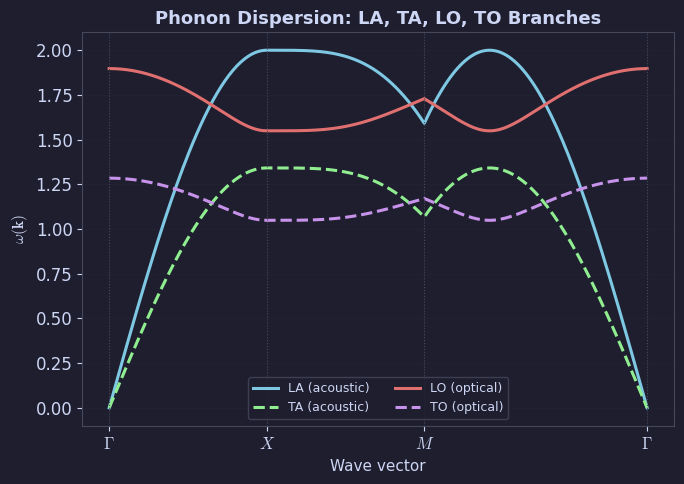

Fig 08 saved.


In [9]:

# Fig 08: 3D phonon dispersion along high-symmetry path
# Simple cubic: 3 branches (1 LA + 2 TA) from monatomic TB model
# LA: omega = 2*sqrt(kappa/m)|sin(ka/2)|
# TA: omega = 2*sqrt(kappa_perp/m)|sin(ka/2)| (softer)
# For diatomic: doubles -> 3 acoustic + 3 optical

a = 1.0
kappa_LA  = 1.0
kappa_TA  = 0.45   # transverse springs are softer
kappa_opt_LA = 1.2
kappa_opt_TA = 0.55
M = 2.0; m = 1.0   # for diatomic optical branches

# Path: Gamma -> X -> M -> Gamma (2D analogue)
N = 80
G = np.array([0., 0.])
X = np.array([np.pi/a, 0.])
M_pt = np.array([np.pi/a, np.pi/a])

p1 = [G + t*(X-G)    for t in np.linspace(0,1,N)]
p2 = [X + t*(M_pt-X) for t in np.linspace(0,1,N)]
p3 = [M_pt + t*(G-M_pt) for t in np.linspace(0,1,N)]
kpath = np.array(p1 + p2[1:] + p3[1:])
dist  = np.cumsum([0]+[np.linalg.norm(kpath[i+1]-kpath[i])
                       for i in range(len(kpath)-1)])

def ac_branch(kpath, kappa, a):
    return 2*np.sqrt(kappa) * np.abs(np.sin(np.linalg.norm(kpath, axis=1)*a/2))

def opt_branch(kpath, kappa, M, m, a):
    mu = M*m/(M+m)
    k_mag = np.linalg.norm(kpath, axis=1)
    disc = np.clip(1 - 4*(mu**2)/(M*m)*np.sin(k_mag*a/2)**2, 0, None)
    return np.sqrt(kappa/mu * (1 + np.sqrt(disc)))

omega_LA  = ac_branch(kpath, kappa_LA,  a)
omega_TA  = ac_branch(kpath, kappa_TA,  a)
omega_LO  = opt_branch(kpath, kappa_opt_LA, M, m, a)
omega_TO  = opt_branch(kpath, kappa_opt_TA, M, m, a)

fig, ax = plt.subplots(figsize=(7, 5))

ax.plot(dist, omega_LA,  color=BLUE,   lw=2.2, label='LA (acoustic)')
ax.plot(dist, omega_TA,  color=GREEN,  lw=2.2, label='TA (acoustic)', ls='--')
ax.plot(dist, omega_LO,  color=RED,    lw=2.2, label='LO (optical)')
ax.plot(dist, omega_TO,  color=PURPLE, lw=2.2, label='TO (optical)', ls='--')

tick_pos  = [0, dist[N-1], dist[2*N-2], dist[-1]]
tick_labs = [r'$\Gamma$', r'$X$', r'$M$', r'$\Gamma$']
for tp in tick_pos: ax.axvline(tp, color='#45475a', lw=0.8, ls=':')
ax.set_xticks(tick_pos); ax.set_xticklabels(tick_labs, fontsize=12)
ax.set_xlabel('Wave vector', fontsize=11)
ax.set_ylabel(r'$\omega(\mathbf{k})$', fontsize=11)
ax.set_title('Phonon Dispersion: LA, TA, LO, TO Branches', color='#cdd6f4')
ax.legend(fontsize=9, facecolor=BG, edgecolor='#45475a', labelcolor='#cdd6f4',
          ncol=2)
ax.grid(True, alpha=0.2)

plt.tight_layout()
SAVE('fig08_phonon_dispersion_3d.png'); plt.show(); print('Fig 08 saved.')


## Fig 09 — Phonon DOS and Thermal Properties

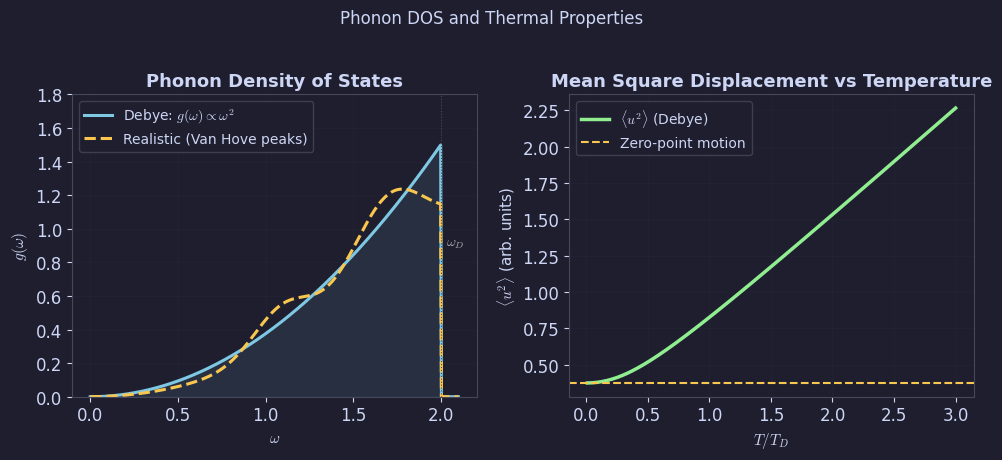

Fig 09 saved.


In [10]:

# Fig 09: Phonon DOS comparison — Debye (omega^2) vs actual + Debye T^3
# and thermal energy / mean displacement


k_B = 1.; hbar = 1.
omega_D = 2.0   # Debye cutoff

omega = np.linspace(0, omega_D*1.05, 500)

# Debye DOS: g(omega) = 3*N*omega^2/omega_D^3 for omega < omega_D
g_debye = np.where(omega <= omega_D,
                   3 * omega**2 / omega_D**3,
                   0.0)

# "Realistic" DOS: van Hove singularities at zone boundary
# Approximate: g ~ omega^2 at low omega, peaks near omega_D
omega_nn = omega[omega <= omega_D]
g_real   = np.zeros_like(omega)
if len(omega_nn) > 0:
    g_real[:len(omega_nn)] = (3*omega_nn**2/omega_D**3
                               + 0.8 * np.exp(-((omega_nn-omega_D*0.85)/(0.15*omega_D))**2)
                               + 0.4 * np.exp(-((omega_nn-omega_D*0.55)/(0.12*omega_D))**2))
    # Normalise
    norm = np.trapezoid(g_real, omega)
    if norm > 0: g_real /= norm

fig, axes = plt.subplots(1, 2, figsize=(10, 4.5))

ax = axes[0]
ax.plot(omega, g_debye, color=BLUE,   lw=2.2,
        label=r'Debye: $g(\omega)\propto\omega^2$')
ax.plot(omega, g_real,  color=YELLOW, lw=2.2, ls='--',
        label='Realistic (Van Hove peaks)')
ax.axvline(omega_D, color='#45475a', lw=0.8, ls=':')
ax.text(omega_D+0.03, 0.9, r'$\omega_D$', color='#aaa', fontsize=10)
ax.fill_between(omega, 0, g_debye, color=BLUE, alpha=0.10)
ax.set_xlabel(r'$\omega$', fontsize=11)
ax.set_ylabel(r'$g(\omega)$', fontsize=11)
ax.set_title('Phonon Density of States', color='#cdd6f4')
ax.legend(fontsize=10, facecolor=BG, edgecolor='#45475a', labelcolor='#cdd6f4')
ax.set_ylim(0, 1.8)
ax.grid(True, alpha=0.2)

# Thermal energy <u^2> = hbar/(2*m*omega) * coth(hbar*omega/2kT)
# Sum over all modes ~ integral with g(omega)
T_arr = np.linspace(0.01, 3.0, 300)

def mean_sq_disp(T, omega_D=2.0, n_omega=200):
    oms = np.linspace(0.01, omega_D, n_omega)
    g   = 3*oms**2/omega_D**3
    x   = hbar*oms / (k_B*T)
    # <u^2> ~ int g(omega)/(omega) * (nBE + 1/2) domega
    nBE = 1.0/(np.exp(x) - 1 + 1e-12)
    integrand = g/oms * (nBE + 0.5)
    return np.trapezoid(integrand, oms)

u2_arr = np.array([mean_sq_disp(T) for T in T_arr])

ax2 = axes[1]
ax2.plot(T_arr, u2_arr, color=GREEN, lw=2.5,
         label=r'$\langle u^2\rangle$ (Debye)')
ax2.axhline(mean_sq_disp(0.01), color=YELLOW, lw=1.5, ls='--',
            label='Zero-point motion')
ax2.set_xlabel(r'$T/T_D$', fontsize=11)
ax2.set_ylabel(r'$\langle u^2\rangle$ (arb. units)', fontsize=11)
ax2.set_title('Mean Square Displacement vs Temperature', color='#cdd6f4')
ax2.legend(fontsize=10, facecolor=BG, edgecolor='#45475a', labelcolor='#cdd6f4')
ax2.grid(True, alpha=0.2)

plt.suptitle('Phonon DOS and Thermal Properties', color='#cdd6f4',
             fontsize=12, y=1.02)
plt.tight_layout()
SAVE('fig09_phonon_dos_thermal.png'); plt.show(); print('Fig 09 saved.')


## Fig 10 — Resistivity from Phonon Scattering

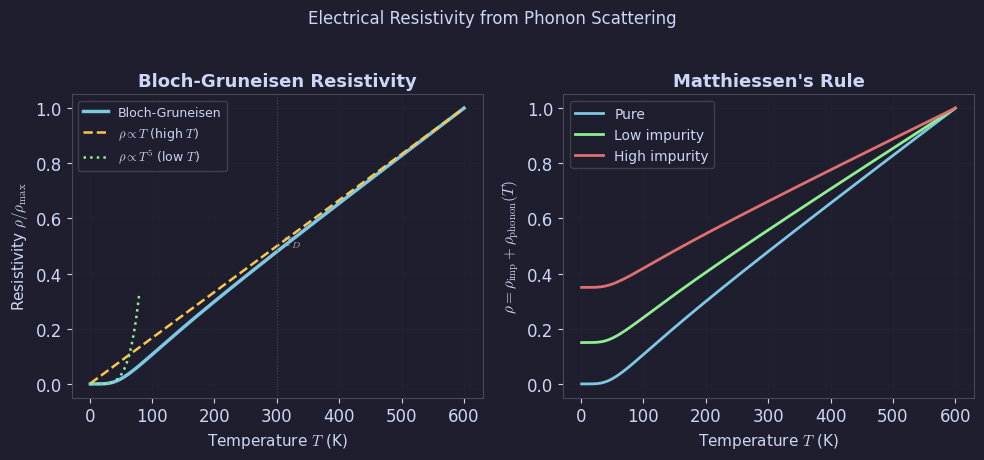

Fig 10 saved.


In [11]:

# Fig 10: Phonon scattering and electrical resistivity
# Bloch-Gruneisen: rho ~ T^5 at low T (only low-q phonons), T at high T
# Also show: Umklapp vs Normal processes

from scipy.integrate import quad

def bloch_gruneisen(T, T_D=300., rho_0=1.):
    if T < 1e-3: return 0.
    x_D = T_D / T
    def integrand(x):
        ex = np.exp(x)
        return x**5 / ((ex-1)*(1-1/ex+1e-30))
    result, _ = quad(integrand, 1e-5, x_D)
    return rho_0 * (T/T_D)**5 * result

T_arr = np.linspace(1, 600, 300)
rho_BG = np.array([bloch_gruneisen(T, T_D=300.) for T in T_arr])
rho_BG /= rho_BG.max()

# High-T linear limit: rho ~ T
rho_linear = T_arr / T_arr.max()

# Low-T T^5 reference
T_low  = T_arr[T_arr < 80]
rho_T5 = (T_low/80)**5 * rho_BG[T_arr < 80][0] / (T_low[0]/80)**5

fig, axes = plt.subplots(1, 2, figsize=(10, 4.5))

ax = axes[0]
ax.plot(T_arr, rho_BG,     color=BLUE,   lw=2.5, label='Bloch-Gruneisen')
ax.plot(T_arr, rho_linear, color=YELLOW, lw=1.8, ls='--',
        label=r'$\rho\propto T$ (high $T$)')
ax.plot(T_low, rho_T5/rho_T5[0]*rho_BG[0], color=GREEN, lw=1.8, ls=':',
        label=r'$\rho\propto T^5$ (low $T$)')
ax.axvline(300, color='#45475a', lw=0.8, ls=':')
ax.text(310, 0.5, r'$T_D$', color='#aaa', fontsize=10)
ax.set_xlabel('Temperature $T$ (K)', fontsize=11)
ax.set_ylabel(r'Resistivity $\rho/\rho_{\rm max}$', fontsize=11)
ax.set_title('Bloch-Gruneisen Resistivity', color='#cdd6f4')
ax.legend(fontsize=9, facecolor=BG, edgecolor='#45475a', labelcolor='#cdd6f4')
ax.grid(True, alpha=0.2)

# Matthiessen's rule: rho_total = rho_impurity + rho_phonon(T)
rho_imp_vals = [0.0, 0.15, 0.35]
ax2 = axes[1]
for rho_imp, col, lbl in zip(rho_imp_vals,
        [BLUE, GREEN, RED],
        ['Pure', 'Low impurity', 'High impurity']):
    ax2.plot(T_arr, rho_imp + rho_BG*(1-rho_imp),
             color=col, lw=2.0, label=lbl)
ax2.set_xlabel('Temperature $T$ (K)', fontsize=11)
ax2.set_ylabel(r'$\rho = \rho_{\rm imp} + \rho_{\rm phonon}(T)$', fontsize=11)
ax2.set_title("Matthiessen's Rule", color='#cdd6f4')
ax2.legend(fontsize=10, facecolor=BG, edgecolor='#45475a', labelcolor='#cdd6f4')
ax2.grid(True, alpha=0.2)

plt.suptitle('Electrical Resistivity from Phonon Scattering',
             color='#cdd6f4', fontsize=12, y=1.02)
plt.tight_layout()
SAVE('fig10_resistivity.png'); plt.show(); print('Fig 10 saved.')


---
## ZIP & Download

In [12]:

import shutil, os
z = shutil.make_archive('ch04_figures','zip','figures/ch04')
print(f'ZIP: {z}, {os.path.getsize(z)//1024} KB')
try:
    from google.colab import files
    files.download('ch04_figures.zip')
    print('Download triggered.')
except ImportError:
    print('Not in Colab — ch04_figures.zip in working directory.')


ZIP: /home/claude/ch04_figures.zip, 939 KB
Not in Colab — ch04_figures.zip in working directory.
